In [50]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage.exposure import match_histograms

In [51]:
def generate_histogram(image):
    histogram = cv2.calcHist([image], [0], None, [256], [0, 256])
    return histogram

## Generate Histogram

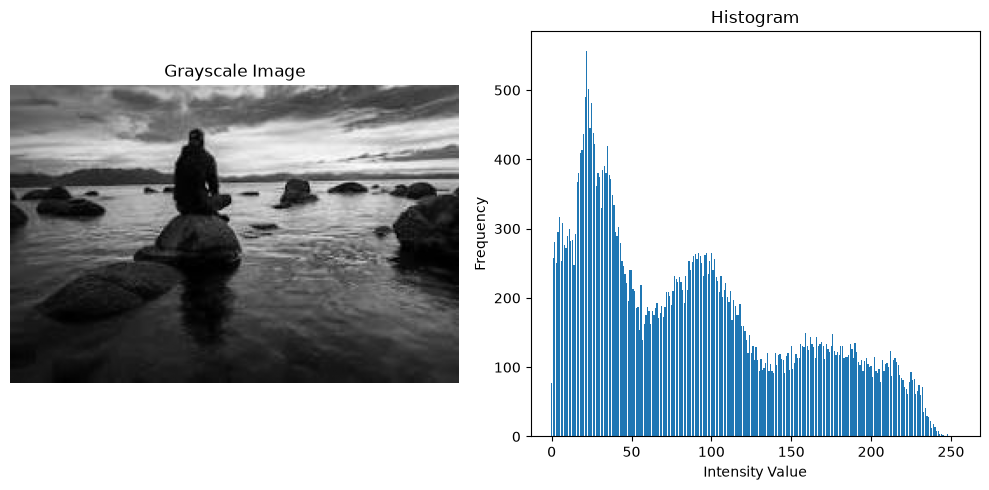

In [52]:
image_path = 'images.jpg'
image = cv2.imread(image_path)

gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
histogram = generate_histogram(gray_image)

intensity_values = np.arange(256)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.bar(intensity_values, histogram.ravel())
plt.title('Histogram')
plt.xlabel('Intensity Value')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


## Normalized Histogram

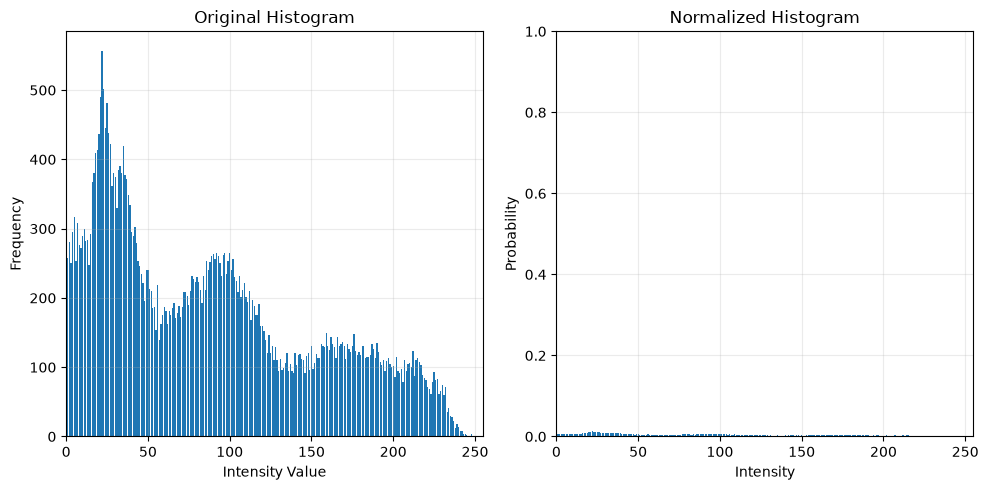

In [53]:
total_pixels = gray_image.size
normalized_histogram = histogram / total_pixels

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)

plt.bar(intensity_values, histogram)
plt.title('Original Histogram')
plt.xlabel('Intensity Value')
plt.ylabel('Frequency')
plt.xlim([0,255])
plt.grid(alpha=0.25)

plt.subplot(1, 2, 2)
plt.bar(intensity_values, normalized_histogram)
plt.title("Normalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("Probability")
plt.xlim([0, 255])
plt.ylim([0, 1])
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Equlization Histogram

In [54]:
def perform_histogram_equalization(image):
    equalized_image = cv2.equalizeHist(image)
    return equalized_image 

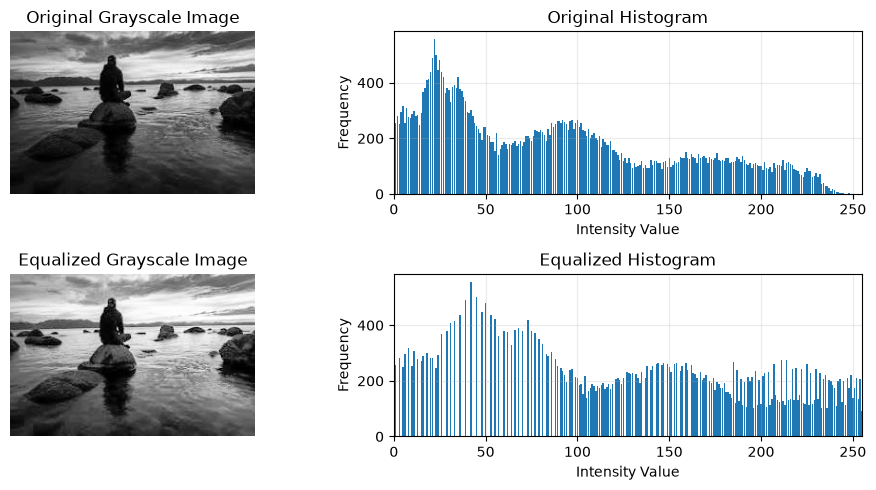

In [ ]:
equalized_image = perform_histogram_equalization(gray_image)

original_histogram = generate_histogram(gray_image)
equalized_histogram = generate_histogram(equalized_image)

plt.figure(figsize=(10, 5))
plt.subplot(2,2,1)

plt.imshow(gray_image, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(2,2,2)
plt.bar(intensity_values, original_histogram)
plt.title('Original Histogram')
plt.xlabel('Intensity Value')
plt.ylabel('Frequency')
plt.xlim([0, 255])
plt.grid(alpha=0.25)

plt.subplot(2,2,3)
plt.imshow(equalized_image, cmap='gray')
plt.title('Equalized Grayscale Image')
plt.axis('off')

plt.subplot(2,2,4)
plt.bar(intensity_values, equalized_histogram)
plt.title('Equalized Histogram')
plt.xlabel('Intensity Value')
plt.ylabel('Frequency')
plt.xlim([0, 255])
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## Histogram Matching

In [56]:
ref_image_path = 'image_ref.jpg'
ref_image = cv2.imread(ref_image_path)
ref_gray_image = cv2.cvtColor(ref_image, cv2.COLOR_BGR2GRAY)

In [57]:
matched_image = match_histograms(gray_image, ref_gray_image)
matched_image.dtype

dtype('float64')

In [58]:
matched_image = np.uint8(matched_image)

In [59]:
original_histogram = generate_histogram(gray_image)
ref_gray_image_histogram = generate_histogram(ref_gray_image)
matched_histogram = generate_histogram(matched_image)

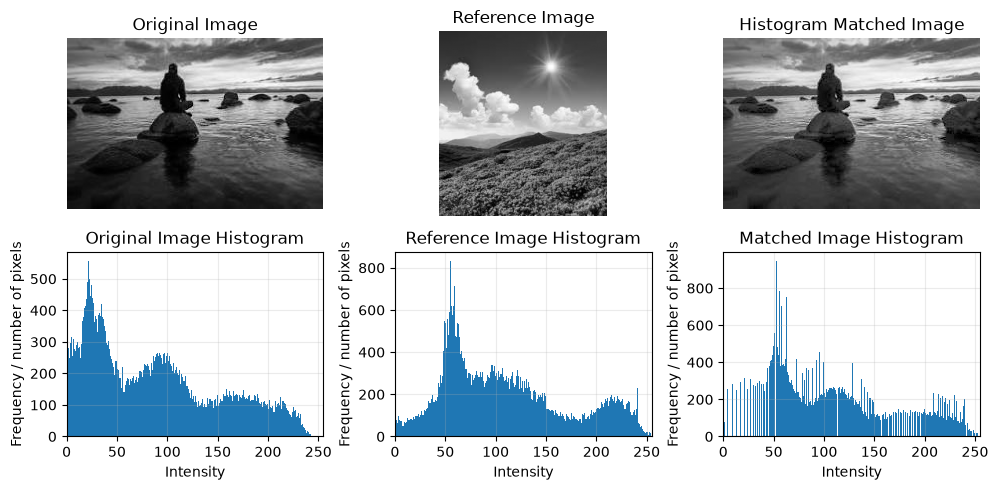

In [60]:
plt.figure(figsize=(10, 5))

plt.subplot(2, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

# Display the reference image
plt.subplot(2, 3, 2)
plt.imshow(ref_gray_image, cmap="gray")
plt.title("Reference Image")
plt.axis("off")

# Display the matched image
plt.subplot(2, 3, 3)
plt.imshow(matched_image, cmap="gray")
plt.title("Histogram Matched Image")
plt.axis("off")

# Display the original histogram
plt.subplot(2, 3, 4)
plt.bar(intensity_values, original_histogram, width=1)
plt.title("Original Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency / number of pixels")
plt.xlim([0, 255])
plt.grid(alpha=0.25)

# Display the reference histogram
plt.subplot(2, 3, 5)
plt.bar(intensity_values, ref_gray_image_histogram, width=1)
plt.title("Reference Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency / number of pixels")
plt.xlim([0, 255])
plt.grid(alpha=0.25)

# Display the matched histogram
plt.subplot(2, 3, 6)
plt.bar(intensity_values, matched_histogram, width=1)
plt.title("Matched Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency / number of pixels")
plt.xlim([0, 255])
plt.grid(alpha=0.25)

# Adjust spacing
plt.tight_layout()

# Display the results
plt.show()